# Add Interactivity: User Input and Callbacks

**CISC7204 Assignment 02 – Module 04 Lab 03**

## Objectives
- Work with Dash Callbacks

**Estimated time needed:** 45 minutes

## Dataset Used
[Airline Reporting Carrier On-Time Performance](airline_data.csv) (local file, same directory as this notebook)

## Theme
Extract the average monthly arrival delay time and see how it changes over the year. The year range is from 2010 to 2020.

## Task 1 – Read the data

Import the required libraries and read the dataset from the local `airline_data.csv` file.

In [1]:
# Import required libraries
import pandas as pd
import plotly.graph_objects as go
import dash
from dash import dcc
from dash import html
from dash.dependencies import Input, Output

# Read the airline data into the pandas dataframe (local file)
airline_data = pd.read_csv('airline_data.csv',
                           encoding = "ISO-8859-1",
                           dtype={'Div1Airport': str, 'Div1TailNum': str,
                                  'Div2Airport': str, 'Div2TailNum': str})
print('Data loaded. Shape:', airline_data.shape)

Data loaded. Shape: (27000, 110)


## Task 2 – Create the Dash application and get the layout

Layout components:
- Application title using `html.H1()`: `Airline Performance Dashboard`, center aligned, color `#503D36`, font-size 40
- Input component using `dcc.Input()`: id `input-year`, default value `2010`, type `number`
- Output component using `dcc.Graph()`: id `line-plot`

In [2]:
# Create a dash application
app = dash.Dash(__name__)

app.layout = html.Div(children=[html.H1('Airline Performance Dashboard', style={'textAlign': 'center', 'color': '#503D36', 'font-size': 40}),
                                html.Div(["Input Year: ", dcc.Input(id='input-year', value='2010',
                                type='number', style={'height':'50px', 'font-size': 35}),],
                                style={'font-size': 40}),
                                html.Br(),
                                html.Br(),
                                html.Div(dcc.Graph(id='line-plot')),
                                ])
print('Dash app layout created.')

Dash app layout created.


## Task 3 – Add the application callback function

The callback takes the entered year as input and returns a line chart of the average monthly arrival delay for that year.

In [3]:
# add callback decorator
@app.callback(Output(component_id='line-plot', component_property='figure'),
              Input(component_id='input-year', component_property='value'))

# Add computation to callback function and return graph
def get_graph(entered_year):
    # Select data based on the entered year
    df = airline_data[airline_data['Year']==int(entered_year)]

    # Group the data by Month and compute average over arrival delay time.
    line_data = df.groupby('Month')['ArrDelay'].mean().reset_index()

    fig = go.Figure(data=go.Scatter(x=line_data['Month'], y=line_data['ArrDelay'], mode='lines', marker=dict(color='green')))
    fig.update_layout(title='Month vs Average Flight Delay Time', xaxis_title='Month', yaxis_title='ArrDelay')
    return fig

### Demo: invoke the callback logic directly (2010 and 2019) to show the generated chart in this notebook

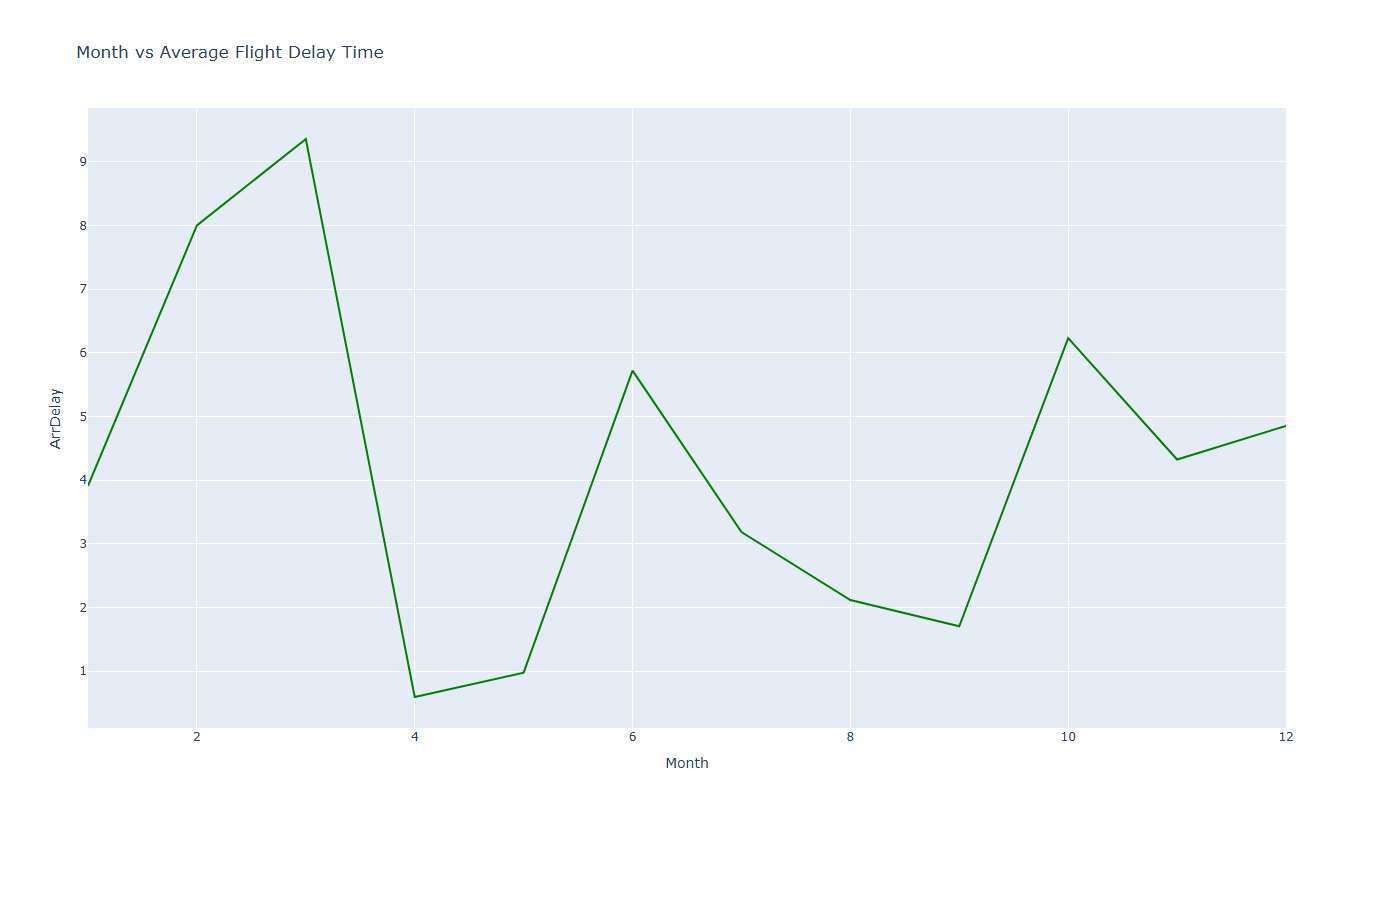

In [4]:
fig = get_graph(2010)
fig.show()

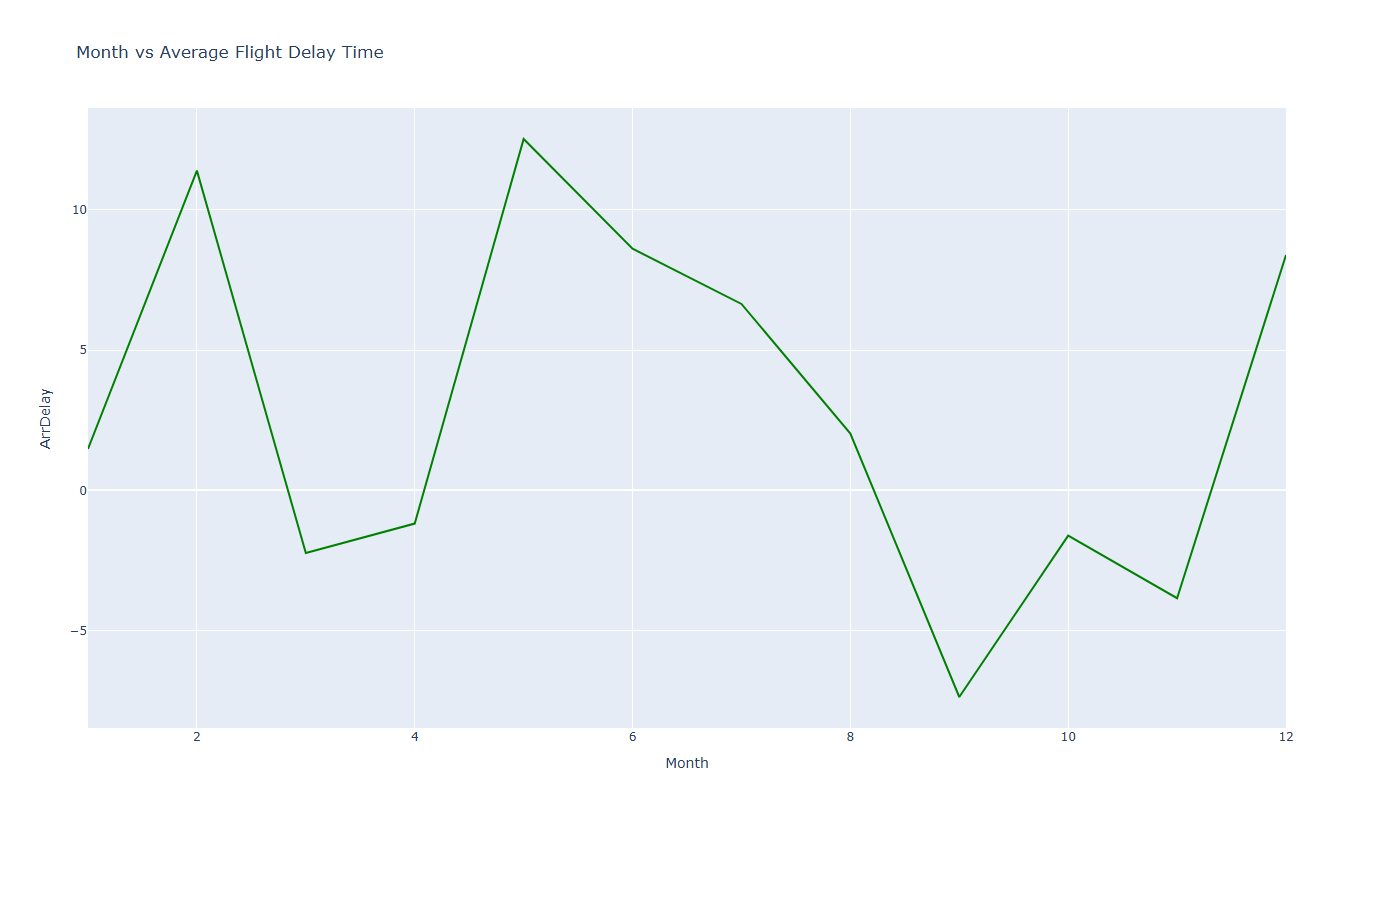

In [5]:
fig = get_graph(2019)
fig.show()

## Run the application

The application can be run as a standalone script (e.g. `python dash_interactivity.py`). Inside this notebook the server is **not** started to avoid blocking the kernel.

```python
if __name__ == '__main__':
    app.run()
```

In [6]:
# Run the app (commented out in the notebook to avoid blocking the kernel)
# if __name__ == '__main__':
#     app.run()

## Task 4 – Practice Exercise: Bar Chart Dashboard

Create a new dashboard that shows the **total number of flights to each destination state** for the selected year, split by reporting airline.

In [7]:
# Practice exercise: bar plot dashboard
import plotly.express as px

app2 = dash.Dash(__name__)
app2.layout = html.Div(children=[html.H1('Total number of flights to the destination state split by reporting airline',
                                 style={'textAlign': 'center', 'color': '#503D36', 'font-size': 40}),
                                 html.Div(["Input Year: ", dcc.Input(id='input-year', value='2010',
                                 type='number', style={'height':'50px', 'font-size': 35}),],
                                 style={'font-size': 40}), html.Br(), html.Br(),
                                 html.Div(dcc.Graph(id='bar-plot')),])

@app2.callback(Output(component_id='bar-plot', component_property='figure'),
               Input(component_id='input-year', component_property='value'))
def get_graph_bar(entered_year):
    df = airline_data[airline_data['Year']==int(entered_year)]
    bar_data = df.groupby('DestState')['Flights'].sum().reset_index()
    fig = px.bar(bar_data, x="DestState", y="Flights", title='Total number of flights to the destination state split by reporting airline')
    fig.update_layout(title='Flights to Destination State', xaxis_title='DestState', yaxis_title='Flights')
    return fig

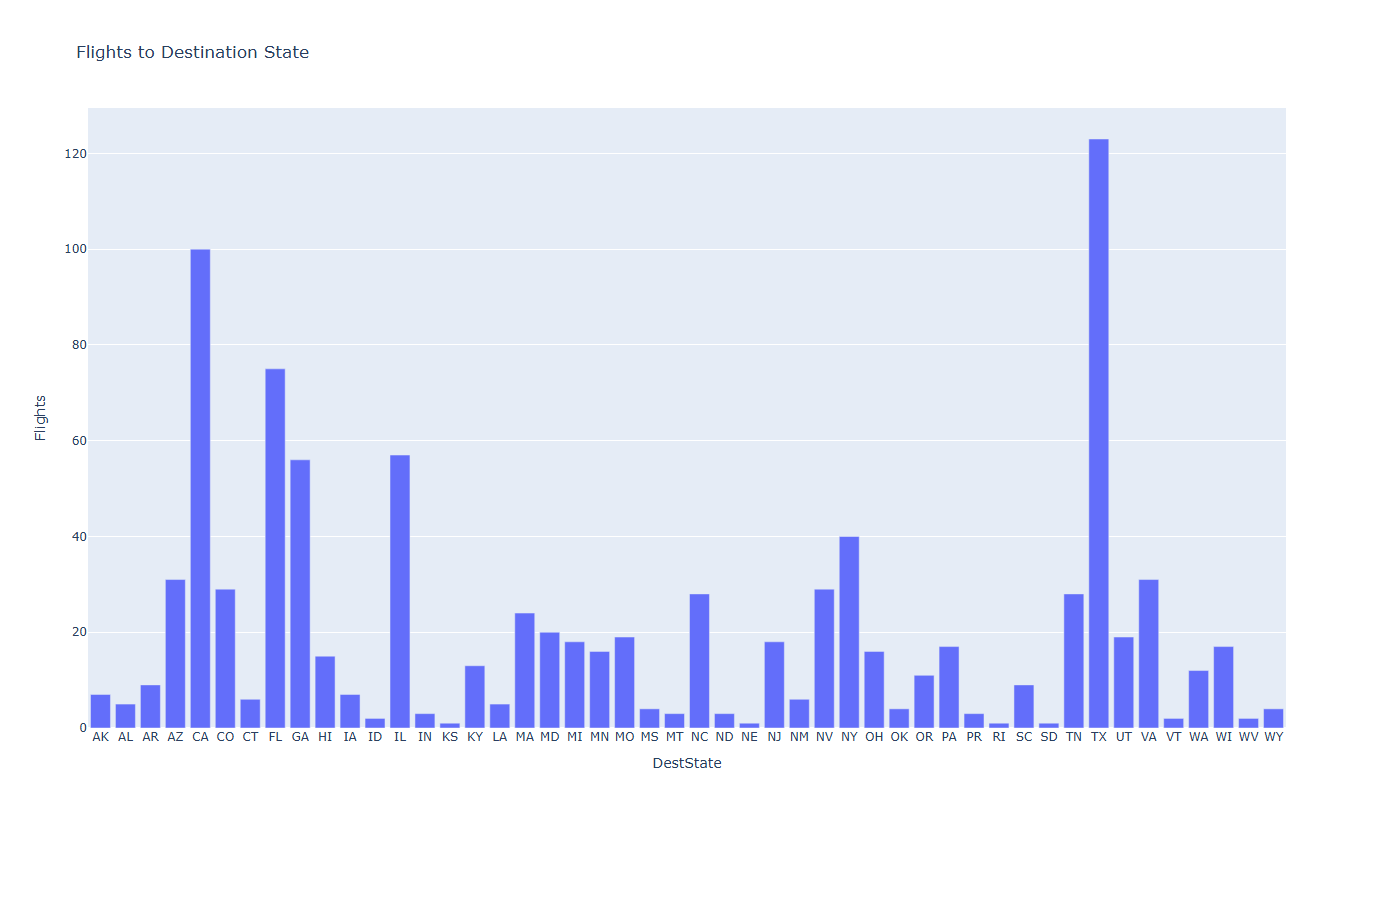

In [8]:
# Demo: show the bar chart for 2010
get_graph_bar(2010).show()

In [9]:
# Run the practice app (commented out in the notebook to avoid blocking the kernel)
# if __name__ == '__main__':
#     app2.run()

### Summary
- Implemented a Dash application with user input (`dcc.Input`) and a callback function
- The line chart updates in real time based on the entered year
- Practice exercise: bar chart of total flights to destination state per selected year